In [2]:
# Importing Datsets
import tensorflow as tf
from keras.datasets import mnist

# Load Data
(x_train,y_train),(x_test,y_test)=mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [3]:
print(x_train.shape)
print(y_train.shape)
print(x_test.shape)
print(y_test.shape)

(60000, 28, 28)
(60000,)
(10000, 28, 28)
(10000,)


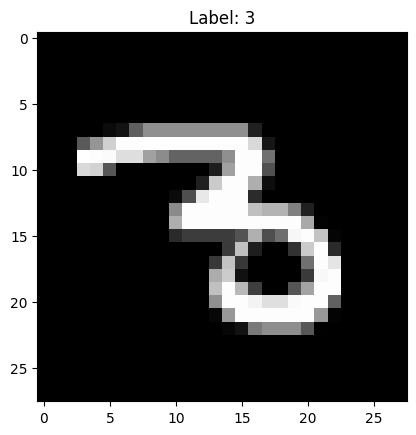

In [4]:
import matplotlib.pyplot as plt

plt.imshow(x_train[30],cmap='gray')
plt.title(f"Label: {y_train[30]}")
plt.show()

In [5]:
print(type(y_train))

<class 'numpy.ndarray'>


In [6]:
print(y_train)

[5 0 4 ... 5 6 8]


In [7]:
import pandas as pd
y_train_1=pd.DataFrame(y_train)
y_train_1.value_counts()

,count
0,
1,6742
7,6265
3,6131
2,5958
9,5949
0,5923
6,5918
8,5851
4,5842


In [8]:
type(x_train)

numpy.ndarray

In [9]:
type(x_train[0])

numpy.ndarray

In [10]:
# Let us apply normalization
x_train = x_train.astype('float32')
x_test = x_test.astype('float32')
x_train = x_train / 255
x_test = x_test / 255
print(x_train.shape)
print(x_test.shape)


(60000, 28, 28)
(10000, 28, 28)


In [12]:
# Let us reshape x_train and x_test
x_train = x_train.reshape(60000, 28*28)
x_test = x_test.reshape(10000, 28*28)
print(x_train.shape)
print(x_test.shape)

(60000, 784)
(10000, 784)


In [15]:
# Let us build sequential Model
from keras.models import Sequential
from keras.layers import Dense

# Define Sequential Model
model=Sequential()

# Let us add input layer
model.add(Dense(units=784,activation='relu',input_dim=28*28))

# Let us add First Hidden layer
model.add(Dense(units=10,activation='relu'))

# Second Hidden layer
model.add(Dense(units=10,activation='relu'))

# let us add output Layer
model.add(Dense(units=10,activation='softmax'))


model.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 784)            │       615,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         7,850 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           110 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 623,510 (2.38 MB)

 Trainable params: 623,510 (2.38 MB)

 Non-trainable params: 0 (0.00 B)

In [16]:
# Let us compile the model
model.compile(optimizer='ADAM',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# ADAM


In [17]:
# Let us fit the model
history = model.fit(x_train,
                    y_train,
                    epochs=15,
                    validation_split=0.2)


Epoch 1/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.9049 - loss: 0.3137 - val_accuracy: 0.9538 - val_loss: 0.1619
Epoch 2/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9674 - loss: 0.1082 - val_accuracy: 0.9690 - val_loss: 0.1025
Epoch 3/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9787 - loss: 0.0694 - val_accuracy: 0.9725 - val_loss: 0.0975
Epoch 4/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.9835 - loss: 0.0503 - val_accuracy: 0.9735 - val_loss: 0.0975
Epoch 5/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9883 - loss: 0.0376 - val_accuracy: 0.9749 - val_loss: 0.0907
Epoch 6/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9903 - loss: 0.0296 - val_accuracy: 0.9687 - val_loss: 0.1271
Epoch 7/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9921 - loss: 0.0242 - val_accuracy: 0.9763 - val_loss: 0.1003
Epoch 8/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9929 - loss: 0.02

In [18]:
# Lets us make the Predictions
model.evaluate(x_test,y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9793 - loss: 0.1096


[0.10964862257242203, 0.9793000221252441]

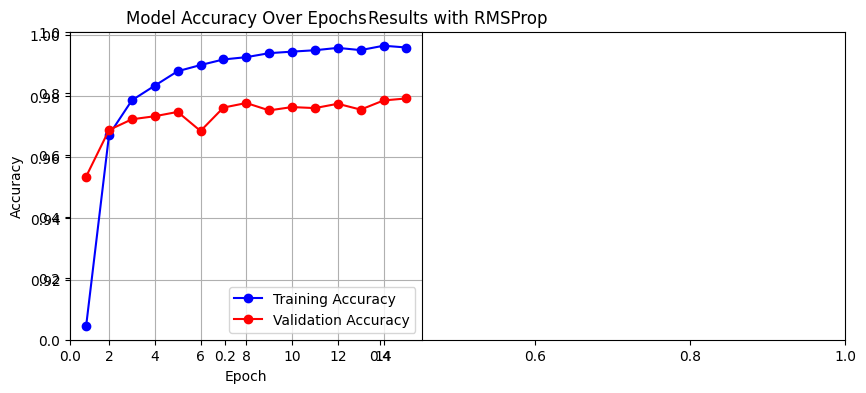

In [21]:
import matplotlib.pyplot as plt

# Extract metrics from the history object
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs = range(1, len(acc) + 1)

# Plot Accuracy
plt.figure(figsize=(10, 4))
plt.title("Results with RMSProp")
plt.subplot(1, 2, 1)
plt.plot(epochs, acc, 'bo-', label='Training Accuracy')
plt.plot(epochs, val_acc, 'ro-', label='Validation Accuracy')
plt.title('Model Accuracy Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

In [23]:
# Let us compile the model
model.compile(optimizer='SGD',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# SGD

In [24]:
# Let us fit the model
history = model.fit(x_train,
                    y_train,
                    epochs=15,
                    validation_split=0.2)


Epoch 1/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9985 - loss: 0.0051 - val_accuracy: 0.9797 - val_loss: 0.1131
Epoch 2/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9991 - loss: 0.0032 - val_accuracy: 0.9797 - val_loss: 0.1124
Epoch 3/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9993 - loss: 0.0024 - val_accuracy: 0.9800 - val_loss: 0.1128
Epoch 4/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9996 - loss: 0.0019 - val_accuracy: 0.9800 - val_loss: 0.1115
Epoch 5/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9996 - loss: 0.0016 - val_accuracy: 0.9805 - val_loss: 0.1115
Epoch 6/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.9997 - loss: 0.0014 - val_accuracy: 0.9806 - val_loss: 0.1114
Epoch 7/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9998 - loss: 0.0011 - val_accuracy: 0.9805 - val_loss: 0.1118
Epoch 8/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9999 - loss: 0.0010 -

In [25]:
# Lets us make the Predictions
model.evaluate(x_test,y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9823 - loss: 0.0968


[0.09684614092111588, 0.9822999835014343]